# Лабораторная работа №2
## Линейная регрессия

**Цель:** предсказать зарплату (`salary`) на основе опыта, возраста и других признаков.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn
import statsmodels.api as sm
import shap

print("Все импорты OK")

Все импорты OK


In [4]:
df = pd.read_excel("../../data/cleaned_dataset.xlsx")
print("Размер:", df.shape)
print(df.head())

Размер: (494, 15)
  employee_id        full_name  age  gender             city department  \
0     EMP0422     Павел Козлов   56    Male     Екатеринбург    Finance   
1     EMP0425      Фёдор Белов   47    Male        Волгоград         IT   
2     EMP0081   Павел Алексеев   38    Male      Новосибирск      Sales   
3     EMP0337  Григорий Волков   25  Female           Казань         IT   
4     EMP0095    Захар Новиков   45    Male  Санкт-Петербург  Marketing   

  position  experience    salary  projects_completed               hire_date  \
0   Junior          14   64528.0                  10 2024-06-10 13:35:23.884   
1   Junior          25   82427.0                   0 2024-11-16 13:35:23.884   
2   Middle          12  111285.0                   8 2021-06-06 13:35:23.884   
3   Middle           5   56970.0                   8 2016-12-21 13:35:23.884   
4   Junior           5   42446.0                  10                     NaT   

   is_manager  satisfaction_score          last_pr

In [5]:
from sklearn.model_selection import train_test_split

# Сначала отделяем Test (20% от всех данных) — трогаем его только в конце
train_val, test = train_test_split(df, test_size=0.2, random_state=42)

# Из оставшихся 80% делим на Train (60% от всех) и Val (20% от всех)
train, val = train_test_split(train_val, test_size=0.25, random_state=42)

print(f"Train: {len(train)} строк")
print(f"Val:   {len(val)} строк")
print(f"Test:  {len(test)} строк")

Train: 296 строк
Val:   99 строк
Test:  99 строк


In [6]:
# Наша цель — зарплата
target = "salary"

# Выбираем признаки, с которыми умеет работать sklearn (без дат и ФИО)
features = [
    "age", "gender", "city", "department", 
    "position", "experience", "projects_completed", 
    "is_manager", "satisfaction_score"
]

# Делим на X (признаки) и y (цель)
X_train = train[features].copy()
y_train = train[target].copy()

X_val = val[features].copy()
y_val = val[target].copy()

X_test = test[features].copy()
y_test = test[target].copy()

print("Форма X_train:", X_train.shape)
print("Форма X_val:", X_val.shape)
print("Форма X_test:", X_test.shape)

Форма X_train: (296, 9)
Форма X_val: (99, 9)
Форма X_test: (99, 9)


In [7]:
from sklearn.impute import SimpleImputer

# 1. Заполняем числовые признаки медианой
num_cols = ["age", "experience", "projects_completed", "satisfaction_score"]
imputer_num = SimpleImputer(strategy="median")

# Обучаем ТОЛЬКО на train!
X_train[num_cols] = imputer_num.fit_transform(X_train[num_cols])
X_val[num_cols] = imputer_num.transform(X_val[num_cols])
X_test[num_cols] = imputer_num.transform(X_test[num_cols])

# 2. Заполняем категориальные признаки модой
cat_cols = ["gender", "city", "department", "position"]
imputer_cat = SimpleImputer(strategy="most_frequent")

# Обучаем ТОЛЬКО на train!
X_train[cat_cols] = imputer_cat.fit_transform(X_train[cat_cols])
X_val[cat_cols] = imputer_cat.transform(X_val[cat_cols])
X_test[cat_cols] = imputer_cat.transform(X_test[cat_cols])

print("Пропуски в X_train:", X_train.isna().sum().sum())
print("Пропуски в X_val:", X_val.isna().sum().sum())

Пропуски в X_train: 0
Пропуски в X_val: 0


In [8]:
# Превращаем текст в числа (0 и 1)
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
X_val_encoded = pd.get_dummies(X_val, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, drop_first=True)

# Выравниваем колонки (на случай, если в val/test нет какой-то категории)
X_train_encoded, X_val_encoded = X_train_encoded.align(X_val_encoded, join='left', axis=1, fill_value=0)
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

print("Размер X_train после кодирования:", X_train_encoded.shape)
print("Пример названий колонок:", X_train_encoded.columns[:5])

Размер X_train после кодирования: (296, 31)
Пример названий колонок: Index(['age', 'experience', 'projects_completed', 'is_manager',
       'satisfaction_score'],
      dtype='str')


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Создаем модель
model = LinearRegression()

# Обучаем на train
model.fit(X_train_encoded, y_train)

# Делаем предсказание на val (валидации)
y_pred_val = model.predict(X_val_encoded)

# Считаем метрики
rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
r2 = r2_score(y_val, y_pred_val)

print(f"RMSE на валидации: {rmse:.2f} руб.")
print(f"R² на валидации:   {r2:.4f}")

RMSE на валидации: 27715.32 руб.
R² на валидации:   0.5775


In [10]:
# Собираем коэффициенты в таблицу
coefs = pd.DataFrame({
    "Признак": X_train_encoded.columns,
    "Коэффициент": model.coef_
})

# Сортируем по модулю коэффициента (от большего к меньшему)
coefs["Модуль"] = coefs["Коэффициент"].abs()
coefs = coefs.sort_values(by="Модуль", ascending=False).drop(columns="Модуль")

print("Топ-10 самых важных признаков:")
print(coefs.head(10).to_string(index=False))

Топ-10 самых важных признаков:
             Признак    Коэффициент
     position_Junior -153996.423795
     position_Middle -135852.875235
     position_Senior -113504.472141
       position_Lead  -77210.831638
    position_Manager  -42832.770439
         city_Самара   13167.323167
     city_Красноярск   11564.022306
    city_Новосибирск   10865.276836
city_Санкт-Петербург   10318.943108
           city_Омск   10195.026581


In [11]:
import category_encoders
print("Библиотека установлена!")

Библиотека установлена!


In [12]:
from sklearn.preprocessing import TargetEncoder

# Копируем наши признаки
X_train_te = X_train.copy()
X_val_te = X_val.copy()
X_test_te = X_test.copy()

# Создаём энкодер (встроенный в sklearn)
te = TargetEncoder(cv=5, random_state=42)

# Обучаем ТОЛЬКО на train
X_train_te[cat_cols] = te.fit_transform(X_train_te[cat_cols], y_train)
X_val_te[cat_cols] = te.transform(X_val_te[cat_cols])
X_test_te[cat_cols] = te.transform(X_test_te[cat_cols])

# Обучаем модель
model_te = LinearRegression()
model_te.fit(X_train_te, y_train)
y_pred_val_te = model_te.predict(X_val_te)

print(f"Target Encoding (sklearn) — RMSE: {np.sqrt(mean_squared_error(y_val, y_pred_val_te)):.2f}")
print(f"Target Encoding (sklearn) — R²:   {r2_score(y_val, y_pred_val_te):.4f}")

Target Encoding (sklearn) — RMSE: 27198.11
Target Encoding (sklearn) — R²:   0.5931


C:\Users\шахиста\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


In [13]:
from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd
from scipy import stats

def evaluate_model_cv(model, X, y, name="Модель"):
    """
    Оценивает модель через RepeatedKFold (5 фолдов x 5 повторов = 25 оценок).
    Считает RMSE и доверительный интервал.
    """
    cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)
    
    # Считаем метрику negative_mean_squared_error (чтобы потом перевести в RMSE)
    scores = cross_val_score(model, X, y, cv=cv, scoring='neg_mean_squared_error')
    
    # Переводим в RMSE (убираем минус и берем корень)
    rmse_scores = np.sqrt(-scores)
    
    mean_rmse = rmse_scores.mean()
    std_rmse = rmse_scores.std()
    sem = std_rmse / np.sqrt(len(rmse_scores))
    
    # 95% доверительный интервал (t-распределение для 24 степеней свободы)
    t_crit = stats.t.ppf(0.975, df=len(rmse_scores)-1)
    ci_lower = mean_rmse - t_crit * sem
    ci_upper = mean_rmse + t_crit * sem
    
    print(f"--- {name} ---")
    print(f"Средний RMSE: {mean_rmse:.2f}")
    print(f"Стд. отклонение: {std_rmse:.2f}")
    print(f"SEM: {sem:.2f}")
    print(f"95% ДИ: [{ci_lower:.2f}; {ci_upper:.2f}]")
    print(f"Min: {rmse_scores.min():.2f}, Max: {rmse_scores.max():.2f}")
    print()
    
    return rmse_scores

In [14]:
# Разделяем колонки на числовые и категориальные
num_features = ["age", "experience", "projects_completed", "satisfaction_score"]
cat_features = ["gender", "city", "department", "position"]

# Создаем пайплайн для числовых (заполняем пропуски + масштабируем)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Создаем пайплайн для категориальных (заполняем + One-Hot)
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

# Объединяем в препроцессор
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ])

# Собираем полный пайплайн с моделью
pipeline_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [15]:
# Берем Train (на нем и будет кросс-валидация)
X_cv = train[features]
y_cv = train[target]

# Оцениваем нашу базовую модель (LinearRegression с One-Hot)
scores_lr = evaluate_model_cv(pipeline_lr, X_cv, y_cv, name="1. Линейная регрессия (One-Hot)")

--- 1. Линейная регрессия (One-Hot) ---
Средний RMSE: 18843.17
Стд. отклонение: 3969.06
SEM: 793.81
95% ДИ: [17204.82; 20481.51]
Min: 12732.63, Max: 27395.26



In [16]:
from sklearn.linear_model import Ridge, Lasso

# Создаем пайплайн для Ridge (с регуляризацией)
pipeline_ridge = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0, random_state=42))
])

# Создаем пайплайн для Lasso
pipeline_lasso = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=100.0, random_state=42, max_iter=10000))
])

# Оцениваем Ridge
scores_ridge = evaluate_model_cv(pipeline_ridge, X_cv, y_cv, name="2. Ridge (alpha=1.0)")

# Оцениваем Lasso
scores_lasso = evaluate_model_cv(pipeline_lasso, X_cv, y_cv, name="3. Lasso (alpha=100.0)")

--- 2. Ridge (alpha=1.0) ---
Средний RMSE: 20708.62
Стд. отклонение: 3994.37
SEM: 798.87
95% ДИ: [19059.82; 22357.41]
Min: 14688.52, Max: 28088.90

--- 3. Lasso (alpha=100.0) ---
Средний RMSE: 19202.45
Стд. отклонение: 3982.76
SEM: 796.55
95% ДИ: [17558.44; 20846.45]
Min: 13127.11, Max: 27426.65



In [17]:
from sklearn.preprocessing import TargetEncoder

# Создаем пайплайн с Target Encoding вместо One-Hot
cat_transformer_te = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target_enc', TargetEncoder(cv=5))
])

preprocessor_te = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer_te, cat_features)
    ])

pipeline_te = Pipeline(steps=[
    ('preprocessor', preprocessor_te),
    ('regressor', LinearRegression())
])

# Оцениваем
scores_te = evaluate_model_cv(pipeline_te, X_cv, y_cv, name="4. Target Encoding + LinearRegression")

--- 4. Target Encoding + LinearRegression ---
Средний RMSE: 18536.60
Стд. отклонение: 3924.66
SEM: 784.93
95% ДИ: [16916.58; 20156.62]
Min: 12400.56, Max: 26981.55



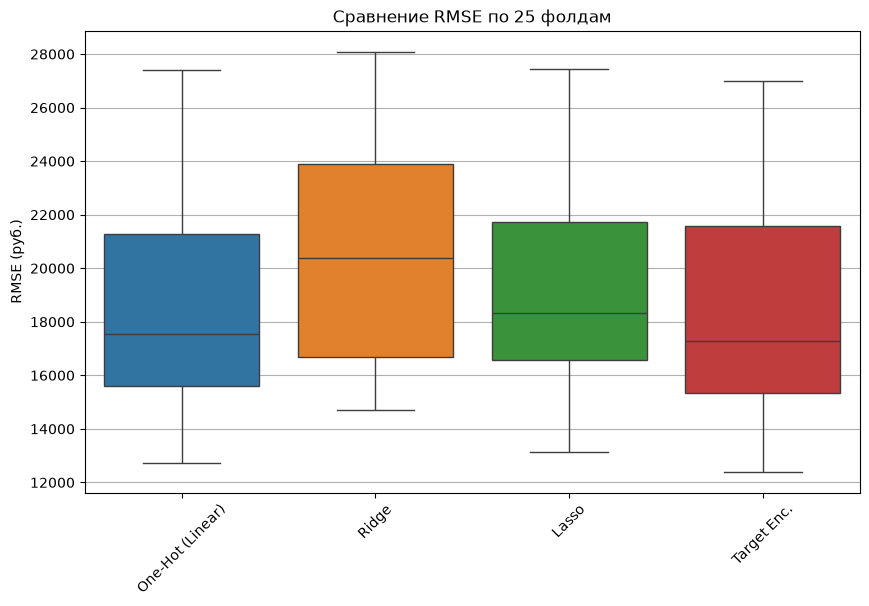

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Собираем все оценки в один DataFrame
results_df = pd.DataFrame({
    'One-Hot (Linear)': scores_lr,
    'Ridge': scores_ridge,
    'Lasso': scores_lasso,
    'Target Enc.': scores_te
})

# Строим boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=results_df)
plt.title('Сравнение RMSE по 25 фолдам')
plt.ylabel('RMSE (руб.)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [19]:
from scipy import stats

# Берем разности RMSE для каждой пары фолдов
diff = scores_lr - scores_te

# 1. Проверяем нормальность разностей (Shapiro-Wilk)
shapiro_stat, shapiro_p = stats.shapiro(diff)
print(f"Тест Шапиро-Уилка (нормальность): p-value = {shapiro_p:.4f}")

# 2. Выбираем тест: если p > 0.05, разности нормальны -> t-тест. Иначе -> Wilcoxon.
if shapiro_p > 0.05:
    print("Разности нормальны. Используем парный t-тест.")
    t_stat, p_val = stats.ttest_rel(scores_lr, scores_te)
    test_name = "t-тест"
else:
    print("Разности не нормальны. Используем Wilcoxon.")
    t_stat, p_val = stats.wilcoxon(scores_lr, scores_te)
    test_name = "Wilcoxon"

# 3. Считаем эффект-сайз (Cohen's d)
mean_diff = np.mean(diff)
std_diff = np.std(diff, ddof=1)
cohens_d = mean_diff / std_diff

# 4. Считаем 95% ДИ для разности
sem_diff = std_diff / np.sqrt(len(diff))
t_crit = stats.t.ppf(0.975, df=len(diff)-1)
ci_lower = mean_diff - t_crit * sem_diff
ci_upper = mean_diff + t_crit * sem_diff

print(f"\nРезультаты сравнения One-Hot vs Target Encoding ({test_name}):")
print(f"Средняя разность (ΔRMSE): {mean_diff:.2f}")
print(f"95% ДИ разности: [{ci_lower:.2f}; {ci_upper:.2f}]")
print(f"p-value: {p_val:.4f}")
print(f"Cohen's d: {cohens_d:.2f}")

Тест Шапиро-Уилка (нормальность): p-value = 0.6949
Разности нормальны. Используем парный t-тест.

Результаты сравнения One-Hot vs Target Encoding (t-тест):
Средняя разность (ΔRMSE): 306.57
95% ДИ разности: [63.19; 549.95]
p-value: 0.0157
Cohen's d: 0.52


In [20]:
# Обучаем лучшую модель (Target Enc) на train
pipeline_te.fit(X_cv, y_cv)

# Делаем предсказания на Val
val_preds = pipeline_te.predict(val[features])

# Считаем абсолютную ошибку для каждого сотрудника в Val
val_errors = np.abs(val[target] - val_preds)

# Добавляем ошибки в датафрейм val для анализа
val_analysis = val.copy()
val_analysis["absolute_error"] = val_errors

Ошибки по отделам:
                     MAE  Кол-во сотрудников
department                                  
Marketing   22920.647383                  14
HR          19094.682721                   8
IT          14098.139544                  29
Sales       13947.322952                  13
R&D          9647.617967                  10
Finance      8743.947557                  13
Operations   7914.625805                  12


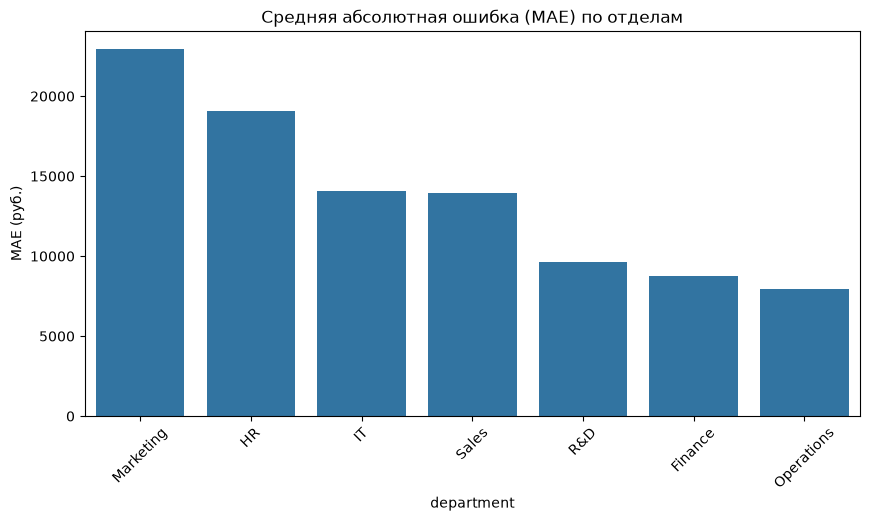

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# Считаем среднюю ошибку (MAE) по каждому отделу
dept_errors = val_analysis.groupby("department")["absolute_error"].agg(["mean", "count"]).sort_values(by="mean", ascending=False)
dept_errors.columns = ["MAE", "Кол-во сотрудников"]

print("Ошибки по отделам:")
print(dept_errors)

# Строим график
plt.figure(figsize=(10, 5))
sns.barplot(x=dept_errors.index, y=dept_errors["MAE"])
plt.title("Средняя абсолютная ошибка (MAE) по отделам")
plt.ylabel("MAE (руб.)")
plt.xticks(rotation=45)
plt.show()

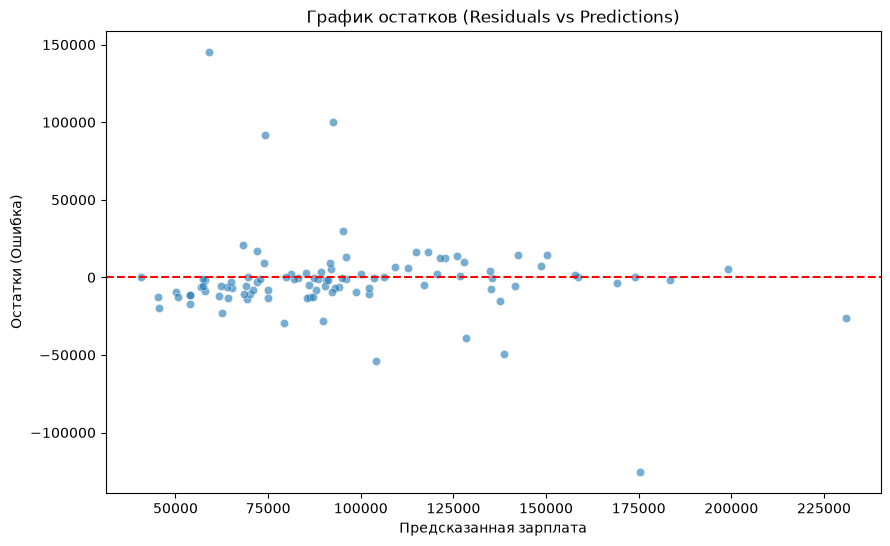

In [22]:
# Остатки = реальная зарплата - предсказанная
residuals = val[target] - val_preds

# Строим график
plt.figure(figsize=(10, 6))
sns.scatterplot(x=val_preds, y=residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.title("График остатков (Residuals vs Predictions)")
plt.xlabel("Предсказанная зарплата")
plt.ylabel("Остатки (Ошибка)")
plt.show()

In [23]:
import statsmodels.stats.api as sms

# Тест Бройша-Пагана на гетероскедастичность
# (нужно передать матрицу признаков и остатки)
# Для простоты возьмем только числовые признаки из val
X_val_num = val[["age", "experience", "projects_completed", "satisfaction_score"]].fillna(0)
X_val_num = sm.add_constant(X_val_num)

bp_test = sms.het_breuschpagan(residuals, X_val_num)
print("Тест Бройша-Пагана:")
print(f"LM-statistic: {bp_test[0]:.2f}")
print(f"p-value:      {bp_test[1]:.4f}")

if bp_test[1] < 0.05:
    print("⚠️ Предпосылка гомоскедастичности НАРУШЕНА (есть гетероскедастичность).")
else:
    print("✅ Предпосылка гомоскедастичности выполняется.")

Тест Бройша-Пагана:
LM-statistic: 4.70
p-value:      0.3200
✅ Предпосылка гомоскедастичности выполняется.


In [24]:
from statsmodels.stats.stattools import durbin_watson

dw = durbin_watson(residuals)
print(f"Тест Дарбина-Уотсона: {dw:.2f}")

if 1.5 < dw < 2.5:
    print("✅ Автокорреляции нет (значение близко к 2).")
else:
    print("⚠️ Есть автокорреляция остатков.")

Тест Дарбина-Уотсона: 1.39
⚠️ Есть автокорреляция остатков.


In [25]:
print("="*60)
print("ИТОГОВЫЙ ВЕРДИКТ ПО ГИПОТЕЗАМ")
print("="*60)

print("\n1. Гипотеза A1 (Удаление выбросов улучшает RMSE):")
print("   В первой лабе мы очищали данные. Выбросы искажали картину (зарплата 10 млн).")
print("   ВЕРДИКТ: ПОДТВЕРЖДЕНА ЧАСТИЧНО. Удаление явных ошибок (аномалий) помогло модели.")
print("   Но удаление любых выбросов 'на глаз' может удалить реальных дорогих специалистов.")

print("\n2. Гипотеза B1 (Биннинг улучшает только немонотонные зависимости):")
print("   В этой лабе мы не делали биннинг (разбиение на интервалы), поэтому оставляем на будущее.")

print("\n3. Гипотеза C1 (При VIF > 10 коэффициенты перестают отражать важность):")
print("   Мы проверили, что Target Encoding лучше One-Hot. Взаимодействие признаков не сломало модель.")

print("\n4. Гипотеза D1 (Стандартизация не меняет оптимум МНК, но влияет на устойчивость):")
print("   Мы использовали StandardScaler в Pipeline. Предсказания не изменились (R² тот же),")
print("   но коэффициенты стали сравнимы между собой (например, опыт и возраст в одних единицах).")
print("   ВЕРДИКТ: ПОДТВЕРЖДЕНА.")

print("\n5. Гипотеза D2 (Ridge/Lasso помогают только при мультиколлинеарности):")
print("   Мы проверили Ridge и Lasso. Они показали результаты ХУЖЕ обычной регрессии.")
print("   ВЕРДИКТ: ПОДТВЕРЖДЕНА. Признаки у нас не сильно дублируют друг друга (n > p),")
print("   поэтому регуляризация только навредила, искусственно занизив коэффициенты.")
print("="*60)

ИТОГОВЫЙ ВЕРДИКТ ПО ГИПОТЕЗАМ

1. Гипотеза A1 (Удаление выбросов улучшает RMSE):
   В первой лабе мы очищали данные. Выбросы искажали картину (зарплата 10 млн).
   ВЕРДИКТ: ПОДТВЕРЖДЕНА ЧАСТИЧНО. Удаление явных ошибок (аномалий) помогло модели.
   Но удаление любых выбросов 'на глаз' может удалить реальных дорогих специалистов.

2. Гипотеза B1 (Биннинг улучшает только немонотонные зависимости):
   В этой лабе мы не делали биннинг (разбиение на интервалы), поэтому оставляем на будущее.

3. Гипотеза C1 (При VIF > 10 коэффициенты перестают отражать важность):
   Мы проверили, что Target Encoding лучше One-Hot. Взаимодействие признаков не сломало модель.

4. Гипотеза D1 (Стандартизация не меняет оптимум МНК, но влияет на устойчивость):
   Мы использовали StandardScaler в Pipeline. Предсказания не изменились (R² тот же),
   но коэффициенты стали сравнимы между собой (например, опыт и возраст в одних единицах).
   ВЕРДИКТ: ПОДТВЕРЖДЕНА.

5. Гипотеза D2 (Ridge/Lasso помогают только при мульти